# Beam Search: The Most Probable Continuation

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/josterri/teaching-nlp-notebooks-sampling/blob/main/03_beam_search.ipynb)

After `It is a truth universally acknowledged that`, GPT-2 small's likeliest next token is `the`, with probability 0.182. Its likeliest continuation of two tokens is `there is`, with probability 0.0159: 5.9 times as probable as `the United` (0.0027), the continuation under greedy decoding.

Run the two setup cells first; on the first run, GPT-2 small (548 MB) is downloaded. In each section, write down an answer to the question, move the sliders, then open the answer. A token is a word or a piece of a word; ↵ is a line break.

In [1]:
# @title Setup: GPT-2 small and the decoding rules (run this cell first)
import functools, html, inspect, subprocess, sys, warnings

warnings.filterwarnings("ignore")
try:
    import transformers  # preinstalled in Colab
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "transformers"], check=True)

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import HTML, display
from huggingface_hub.utils import logging as hub_logging
from transformers import GPT2LMHeadModel, GPT2TokenizerFast
from transformers.utils import logging as hf_logging

hub_logging.set_verbosity_error()
hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
torch.set_grad_enabled(False)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Loading GPT-2 small; on the first run, 548 MB are downloaded ...")
tok = GPT2TokenizerFast.from_pretrained("gpt2")
model = GPT2LMHeadModel.from_pretrained("gpt2").eval().to(DEVICE)
V = len(tok)  # 50,257 tokens

AUSTEN = "It is a truth universally acknowledged that"
PEAKED = "The Prime Minister of the United"
FLAT = "I went to the"
BANK = "The central bank decided to"
PROMPTS = [AUSTEN, PEAKED, FLAT, BANK]

BLUE, ORANGE, AQUA, GREY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#c9c8c2", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e5e0", "axes.axisbelow": True,
    "axes.titlelocation": "left", "axes.titlesize": 9, "legend.frameon": False,
})


def forward(seqs):
    """GPT-2's scores at every position of each token list in `seqs` (all of one length), float64 on the CPU."""
    return model(torch.tensor(seqs, device=DEVICE)).logits.double().cpu()


@functools.lru_cache(maxsize=128)
def logits(text):
    """GPT-2's score z_i for every token i that may follow `text`."""
    z = forward([tok(text).input_ids])[0, -1].numpy()
    z.setflags(write=False)
    return z


def softmax(z, T=1.0):
    """Probabilities from the scores z at temperature T. T = 0 puts all mass on the largest score."""
    if T == 0:
        p = np.zeros(len(z))
        p[np.argmax(z)] = 1.0
        return p
    e = np.exp((np.asarray(z) - np.max(z)) / T)
    return e / e.sum()


def top_k_filter(p, k):
    """Keep the k likeliest tokens (ties at the boundary kept), rescale them to sum to 1."""
    q = np.where(p >= np.sort(p)[-k], p, 0.0)
    return q / q.sum()


def top_p_filter(p, top_p):
    """Keep the smallest set of likeliest tokens whose probabilities add up to at least top_p."""
    order = np.argsort(p)                      # least likely first
    drop = np.cumsum(p[order]) <= 1 - top_p    # the tail holding at most 1 - top_p
    drop[-1] = False                           # the likeliest token always stays
    q = p.copy()
    q[order[drop]] = 0.0
    return q / q.sum()


def min_p_filter(p, p_base):
    """Keep every token whose probability is at least p_base times the largest probability."""
    q = np.where(p >= p_base * p.max(), p, 0.0)
    return q / q.sum()


def penalise(z, seen, theta):
    """Repetition penalty: scores of tokens already in the text, divided by theta if positive, times theta if negative."""
    z = np.array(z)
    s = z[seen]
    z[seen] = np.where(s < 0, s * theta, s / theta)
    return z


def next_token_dist(z, T=0.0, k=0, top_p=1.0, min_p=0.0):
    """The distribution the next token is drawn from: temperature, then top-k, top-p, min-p (k = 0: no top-k)."""
    p = softmax(z, T)
    if k:
        p = top_k_filter(p, k)
    if top_p < 1:
        p = top_p_filter(p, top_p)
    if min_p > 0:
        p = min_p_filter(p, min_p)
    return p


def generate(text, n_tokens=30, T=0.0, k=0, top_p=1.0, min_p=0.0, theta=1.0, n=1, draw=0):
    """n continuations of `text`, token by token. Each is (tokens, GPT-2's probability at T = 1 of each token)."""
    rng = np.random.default_rng(draw)
    start = tok(text).input_ids
    seqs = [list(start) for _ in range(n)]
    probs = [[] for _ in range(n)]
    for _ in range(n_tokens):
        Z = forward(seqs)[:, -1].numpy()
        for s in range(n):
            z = penalise(Z[s], np.unique(seqs[s]), theta) if theta != 1 else Z[s]
            t = int(rng.choice(V, p=next_token_dist(z, T, k, top_p, min_p)))
            probs[s].append(softmax(Z[s])[t])
            seqs[s].append(t)
    out = []
    for seq, pr in zip(seqs, probs):
        new = seq[len(start):]
        end = new.index(tok.eos_token_id) + 1 if tok.eos_token_id in new else len(new)  # stop at <|endoftext|>
        out.append((new[:end], pr[:end]))
    return out


def word(i):
    """Token i as text, without GPT-2's leading space."""
    s = tok.decode([int(i)])
    return s.strip() or repr(s)


def shade(p):
    """Background colour for a token of probability p: white near 1, dark orange at 0.001 and below."""
    level = np.clip(-np.log10(max(p, 1e-12)) / 3, 0, 1)
    r, g, b, _ = plt.get_cmap("Oranges")(0.8 * level)
    return f"rgb({r * 255:.0f},{g * 255:.0f},{b * 255:.0f})"


def show_text(text, tokens, probs, label=""):
    """The prompt in grey, then each new token on a background set by GPT-2's probability of it."""
    spans = "".join(
        f'<span title="probability {p:.3g}" style="background:{shade(p)};color:#0b0b0b">'
        f'{html.escape(tok.decode([t])).replace(chr(10), "↵")}</span>'
        for t, p in zip(tokens, probs))
    head = f'<b style="color:#52514e">{html.escape(label)}</b> ' if label else ""
    display(HTML(
        f'<div style="font-family:Menlo,monospace;font-size:12px;line-height:1.8;background:#fff;'
        f'color:#0b0b0b;padding:4px 8px;margin:2px 0;border-left:3px solid {GREY}">'
        f'{head}<span style="color:#8a8983">{html.escape(text)}</span>{spans}</div>'))


def colour_key():
    cells = "".join(f'<span style="background:{shade(p)};color:#0b0b0b;padding:0 6px">{p:g}</span> '
                    for p in (1, 0.1, 0.01, 0.001))
    display(HTML(f'<div style="font-size:11px;color:#52514e;background:#fff;padding:2px 6px">'
                 f'background: GPT-2\'s probability of each new token at T = 1, before any rule: {cells}</div>'))


def sentences(text, n=3, n_tokens=30, label="", **rule):
    """Print n continuations of `text` under one decoding rule."""
    for tokens, probs in generate(text, n_tokens, n=n, **rule):
        show_text(text, tokens, probs, label)


def bars(ax, p, keep=None, n=20, color=BLUE, order=None, label=None):
    """Bar chart of the n likeliest tokens; tokens outside `keep` in grey."""
    top = np.argsort(-p)[:n] if order is None else order
    colours = [color if keep is None or keep[i] else GREY for i in top]
    ax.bar(np.arange(len(top)), p[top], width=0.7, color=colours, label=label)
    ax.set_xticks(np.arange(len(top)), [word(i) for i in top], rotation=55, ha="right")
    ax.set_ylabel("probability")
    ax.set_xlabel("next token")
    return top


def slider(lo, hi, step, value, name=""):
    kind = widgets.IntSlider if isinstance(step, int) else widgets.FloatSlider
    return kind(min=lo, max=hi, step=step, value=value, description=name, continuous_update=False)


def prompt_box(value=AUSTEN):
    """A text box with the four prompts as suggestions; any other text works too (press Enter)."""
    return widgets.Combobox(value=value, options=PROMPTS, ensure_option=False, description="prompt",
                            continuous_update=False, layout=widgets.Layout(width="90%"))


def explore(f, **controls):
    """Sliders for the arguments of f; the output is redrawn when a slider is released."""
    missing = set(inspect.signature(f).parameters) - set(controls)
    assert not missing, f"no control for {missing}"
    @functools.wraps(f)
    def g(**kwargs):
        if "prompt" in kwargs:
            kwargs["prompt"] = kwargs["prompt"].strip() or AUSTEN  # an empty box falls back to the Austen prompt
        f(**kwargs)
    widgets.interact(g, **controls)


print(f"GPT-2 small loaded: {sum(x.numel() for x in model.parameters()):,} parameters, {V:,} tokens.")

Loading GPT-2 small; on the first run, 548 MB are downloaded ...


GPT-2 small loaded: 124,439,808 parameters, 50,257 tokens.


In [2]:
# @title Charts for the sections below (run this cell)
import textwrap


@functools.lru_cache(maxsize=32)
def two_step_tree(prompt, width=3):
    """The `width` likeliest first tokens and, after each, the `width` likeliest second tokens, with probabilities."""
    ids = tok(prompt).input_ids
    p1 = softmax(forward([ids])[0, -1].numpy())
    tree = []
    for a in np.argsort(-p1)[:width]:
        p2 = softmax(forward([ids + [int(a)]])[0, -1].numpy())
        tree.append((int(a), float(p1[a]), [(int(b), float(p2[b])) for b in np.argsort(-p2)[:width]]))
    return tuple(tree)


def tree_picture(prompt, B=None):
    """The two-step tree; B = None marks the greedy path, a width B marks what beam search keeps."""
    tree = two_step_tree(prompt)
    paths = {(a, b): pa * pb for a, pa, kids in tree for b, pb in kids}
    if B is None:
        kept1 = kept2 = set()
        result = (tree[0][0], tree[0][2][0][0])                               # greedy path
    else:
        kept1 = {a for a, _, _ in tree[:B]}                                   # B likeliest first tokens
        kept2 = set(sorted((ab for ab in paths if ab[0] in kept1), key=paths.get, reverse=True)[:B])
        result = max(kept2, key=paths.get)
    mark = ORANGE if B is None else BLUE
    fig, ax = plt.subplots(figsize=(9, 4.8))
    ax.axis("off")
    ax.set_xlim(-0.35, 3.4)
    ax.set_ylim(-0.8, 9.2)

    def box(x, y, text, colour, bold=False):
        ax.text(x, y, text, ha="left" if x > 1.5 else "center", va="center", fontsize=9,
                fontweight="bold" if bold else "normal", color="#0b0b0b",
                bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=colour, lw=1.5 if bold else 1))

    for j, (a, pa, kids) in enumerate(tree):
        ya = 8 - (3 * j + 1)
        on = a == result[0]
        c1 = mark if on else (BLUE if a in kept1 else GREY)
        ax.plot([0, 1], [4, ya], color=c1, lw=4 if on else 1.5, zorder=1)
        for m, (b, pb) in enumerate(kids):
            yb = 8 - (3 * j + m)
            on2 = (a, b) == result
            c2 = mark if on2 else (BLUE if (a, b) in kept2 else GREY)
            ax.plot([1, 2], [ya, yb], color=c2, lw=4 if on2 else 1.5, zorder=1)
            box(2.02, yb, f"{word(b)}  {pb:.3f}    path {paths[(a, b)]:.4f}", c2, bold=on2)
        box(1, ya, f"{word(a)}\n{pa:.3f}", c1, bold=on)
    box(0, 4, textwrap.fill(f'"{prompt}"', 16), INK)
    ax.text(1, 8.7, "first token", ha="center", color=INK)
    ax.text(2.02, 8.7, "second token, path probability", ha="left", color=INK)
    if B is None:
        ax.set_title("the 3 likeliest tokens at each step; orange: greedy decoding")
    else:
        ax.set_title(f"beam search, B = {B}: blue kept, grey dropped; thick line: result")
    plt.show()
    return result


def show_tree(prompt=AUSTEN):
    tree_picture(prompt)


def show_beam_tree(prompt=AUSTEN, B=1):
    tree_picture(prompt, B)
    tokens, lp = beam_search(prompt, B, n_tokens=2)
    print(f"beam search over all {V:,} tokens, B = {B}: {tok.decode(tokens)!r}, probability {np.exp(lp):.4f}")


def log_softmax_steps(prompt, tokens):
    """log p of each token of a continuation, from one forward pass over prompt and continuation."""
    ids = tok(prompt).input_ids
    L = torch.log_softmax(forward([ids + list(tokens)])[0], -1).numpy()
    return np.array([L[len(ids) - 1 + t, tok_id] for t, tok_id in enumerate(tokens)])


def beam_search(text, B, n_tokens=20):
    """Beam search of width B: the B partial continuations with the largest log P, extended token by token."""
    start = tok(text).input_ids
    beams = [(start, 0.0)]                                                     # (tokens, log P)
    for _ in range(n_tokens):
        L = torch.log_softmax(forward([s for s, _ in beams])[:, -1], -1).numpy()
        L = L + np.array([[lp] for _, lp in beams])                            # log P of every extension
        best = np.argsort(L, axis=None)[::-1][:B]                              # the B largest of B x 50,257
        beams = [(beams[r][0] + [int(c)], L[r, c]) for r, c in zip(*np.unravel_index(best, L.shape))]
    return beams[0][0][len(start):], float(beams[0][1])


def show_beam(prompt=AUSTEN, B=1, n_tokens=20):
    colour_key()
    for b in sorted({1, B}):
        tokens, lp = beam_search(prompt, b, n_tokens)
        show_text(prompt, tokens, np.exp(log_softmax_steps(prompt, tokens)), label=f"B = {b}, log P = {lp:.2f}")

## 1. Two Steps After the Austen Prompt

A continuation of two tokens has the probability of its first token times the probability of its second token after the first: 0.182 × 0.015 = 0.0027 for `the United`. The tree has the three likeliest first tokens and, after each, the three likeliest second tokens. Under greedy decoding, the likeliest token is picked at each step: the orange path.

**Question.** Which of the nine paths has the largest probability, and how many times as probable as the greedy path `the United` is it?

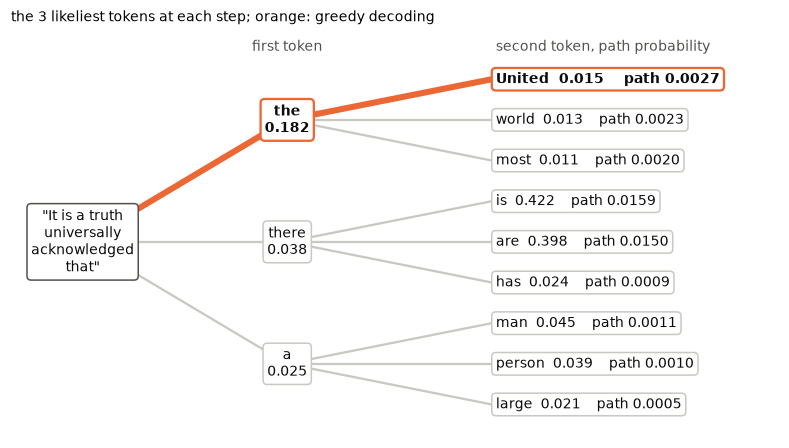

In [3]:
show_tree(AUSTEN)

<details><summary><b>Answer</b></summary>

`there is`: 0.038 × 0.422 = 0.0159, 5.9 times the 0.0027 of `the United`. The first token `there` has a small probability, but after it GPT-2's probability is concentrated on `is` (0.422) and `are` (0.398); after `the`, it is spread, and the likeliest second token, `United`, has 0.015. Under greedy decoding only the first step is compared, and `there` is dropped at once.

</details>

## 2. Beam Search of Width B

Beam search of width B, step by step:

1. keep the B partial continuations with the largest probability;
2. extend each of them by every token, all 50,257;
3. keep the B most probable extensions, and repeat.

B = 1 is greedy decoding. In the tree, kept partial continuations are blue, dropped ones grey, and the result is the thick line. Under the tree: the result of beam search over all 50,257 tokens, the same path as the thick line.

**Question.** What is the smallest B at which the result is `there is`? Try other prompts in the box as well.

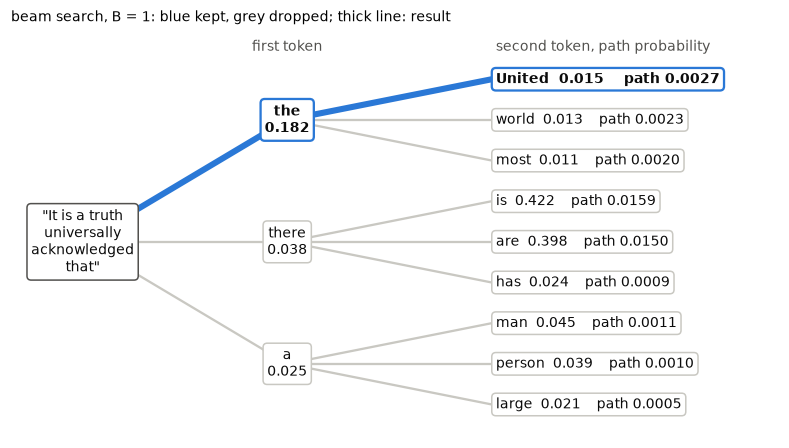

beam search over all 50,257 tokens, B = 1: ' the United', probability 0.0027


In [4]:
show_beam_tree(AUSTEN, B=1)

In [5]:
explore(show_beam_tree, prompt=prompt_box(AUSTEN), B=slider(1, 3, 1, 1))

<details><summary><b>Answer</b></summary>

B = 2. At B = 1, only `the` is kept after the first step, and the result is `the United` (0.0027), the greedy path. At B = 2, `the` and `there` are kept; among their extensions, `there is` (0.0159) and `there are` (0.0150) are the two most probable, and `there is` is the result. B = 3 gives the same result.

</details>

## 3. Longer Continuations

Over 20 tokens, the probability of a continuation is the product of 20 token probabilities. Its logarithm, log P, is the sum of the 20 log-probabilities: a negative number, closer to 0 for a more probable continuation. The first line is greedy decoding (B = 1), the second beam search of width B; each token has a background set by its probability.

**Question.** Move B from 1 to 5 at 20 tokens. Does log P grow with every step of B?

In [6]:
show_beam(AUSTEN, B=5, n_tokens=20)

In [7]:
explore(show_beam, prompt=prompt_box(AUSTEN), B=slider(1, 5, 1, 1), n_tokens=slider(10, 40, 10, 20))

<details><summary><b>Answer</b></summary>

No. log P is −27.77 at B = 1, −27.78 at B = 2, −27.34 at B = 3, and −25.14 at B = 4 and 5. At B = 2 the greedy path is dropped at an intermediate step, and the continuation kept in its place has the lower probability at the end. Under greedy decoding the text is the loop `The United States is a nation of immigrants.`; from B = 2 on, it is `there is no such thing as a ...`.

</details>

## Beam Search Compared With Greedy Decoding

- The probability of a continuation is the product of its token probabilities: 0.038 × 0.422 = 0.0159 for `there is`.
- Under greedy decoding (B = 1), each step is decided alone: `the United`, 0.0027.
- With beam search of width 2, the result is `there is`, 5.9 times as probable.
- Over 20 tokens, log P is −27.78 at B = 2 against −27.77 at B = 1: a wider beam can end on a less probable continuation.